In [1]:
#THIS NOTEBOOK INVESTIGATES:
#1. THE FUSION ENTHALPY BASELINE MODEL'S PERFORMANCE IN THE CONTEXT OF MOLECULE SIZE (MOLECULAR WEIGHT)
#2. THE FUSION ENTHALPY BASELINE MODEL'S PERFORMANCE IN THE CONTEXT OF THE DEGREE OF INTERMOLECULAR HYDROGEN BONDING
#3. THE FUSION ENTHALPY BASELINE MODEL'S PERFORMANCE IN THE CONTEXT OF THE DEGREE OF MOLECULAR FLEXIBILITY (NUMBER OF ROTATABLE BONDS)
#THE BASELINE MODEL AND ITS PREDICTIONS COME FROM run_baseline.py (SEED 0 TEST SET). THE MW-SUBSET MODELS COME FROM run_mw_subsets.py. NOTHING IS TRAINED IN THIS NOTEBOOK

import pandas as pd                          #IMPORTS THE DATA FRAME HANDLING LIBRARY
import numpy as np                           #IMPORTS THE NUMERICAL LIBRARY
import matplotlib.pyplot as plt              #IMPORTS THE PLOTTING LIBRARY
from scipy import stats                      #IMPORTS THE STATISTICS LIBRARY
from rdkit import Chem                       #IMPORTS THE CHEMISTRY LIBRARY
from rdkit.Chem import Descriptors, Lipinski #IMPORTS THE MOLECULAR DESCRIPTOR TOOLS

#PART 1: MOLECULAR WEIGHT ANALYSIS
baseline_predictions = pd.read_csv("dHfus_baseline_predictions.csv")          #SEED 0 BASELINE TEST-SET PREDICTIONS

#IF THE FILE HAS NO RELATIVE ERROR COLUMN, COMPUTE IT
if "rel_error_pct" not in baseline_predictions.columns:
    baseline_predictions["rel_error_pct"] = baseline_predictions["abs_error"] / baseline_predictions["y_true"].abs() * 100

#COMPUTING MOLECULAR WEIGHT FOR EACH TEST-SET MOLECULE
baseline_predictions["MW"] = baseline_predictions["smiles"].apply(lambda s: Descriptors.MolWt(Chem.MolFromSmiles(s)))
print(baseline_predictions["MW"].describe())

count     450.000000
mean      277.077907
std       130.158264
min        67.091000
25%       182.287250
50%       270.284000
75%       333.234250
max      1052.705000
Name: MW, dtype: float64


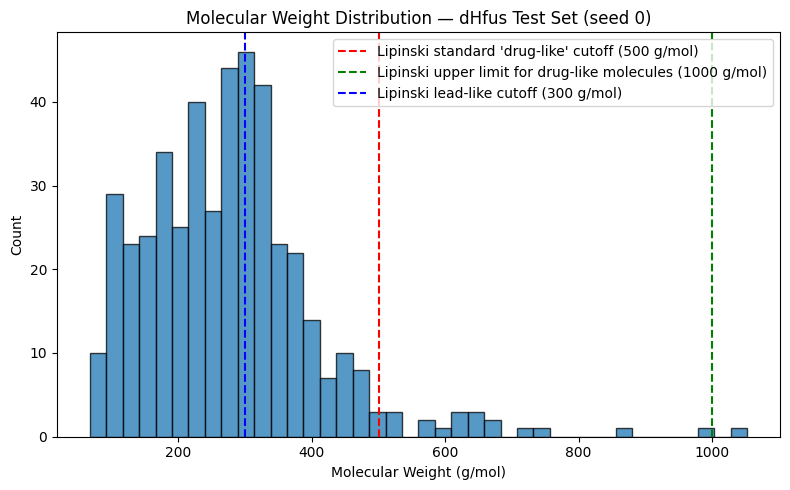

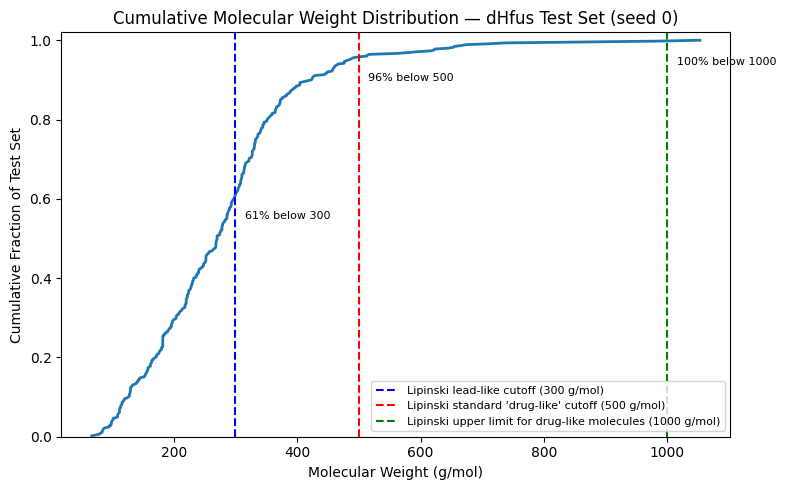

In [2]:
#PLOTTING OF MW DISTRIBUTION FOR CONTEXT
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(baseline_predictions["MW"], bins=40, edgecolor="black", alpha=0.75)
ax.axvline(500, color="red", linestyle="--", label="Lipinski standard 'drug-like' cutoff (500 g/mol)")
ax.axvline(1000, color="green", linestyle="--", label="Lipinski upper limit for drug-like molecules (1000 g/mol)")
ax.axvline(300, color="blue", linestyle="--", label="Lipinski lead-like cutoff (300 g/mol)")
ax.set_xlabel("Molecular Weight (g/mol)")
ax.set_ylabel("Count")
ax.set_title("Molecular Weight Distribution — dHfus Test Set (seed 0)")
ax.legend()
plt.tight_layout()
plt.savefig("plots_dHfus_MW_distribution.png", dpi=150)
plt.show()

#CUMULATIVE FRACTION PLOT FOR MOLECULAR WEIGHT, SAME LIPINSKI REFERENCE LINES AS THE DISTRIBUTION PLOT ABOVE
sorted_mw = np.sort(baseline_predictions["MW"])
cumulative_frac_mw = np.arange(1, len(sorted_mw) + 1) / len(sorted_mw)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(sorted_mw, cumulative_frac_mw, linewidth=2)
for cutoff, color, label in [(300, "blue", "Lipinski lead-like cutoff (300 g/mol)"),
                              (500, "red", "Lipinski standard 'drug-like' cutoff (500 g/mol)"),
                              (1000, "green", "Lipinski upper limit for drug-like molecules (1000 g/mol)")]:
    frac_below = (baseline_predictions["MW"] <= cutoff).mean()
    ax.axvline(cutoff, color=color, linestyle="--", label=label)
    ax.annotate(f"{frac_below:.0%} below {cutoff}", xy=(cutoff, frac_below), xytext=(cutoff + 15, frac_below - 0.06), fontsize=8)
ax.set_xlabel("Molecular Weight (g/mol)")
ax.set_ylabel("Cumulative Fraction of Test Set")
ax.set_title("Cumulative Molecular Weight Distribution — dHfus Test Set (seed 0)")
ax.set_ylim(0, 1.02)
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig("plots_dHfus_MW_cumulative.png", dpi=150)
plt.show()

mw_lipinski_bin
Lead-like (<300)       274
Drug-like (300-500)    157
Extended (500-1000)     18
>1000                    1
Name: count, dtype: int64
             n  mw_range  mean_abs_error  median_abs_error  mean_rel_error  \
mw_bin                                                                       
Small MW   150    67-219        1.140912          0.893604       88.304837   
Medium MW  151   220-313        1.458385          1.042089       21.710519   
Large MW   149  313-1053        2.533323          1.578969       37.602882   

           median_rel_error  
mw_bin                       
Small MW          20.443669  
Medium MW         15.952126  
Large MW          21.163766  


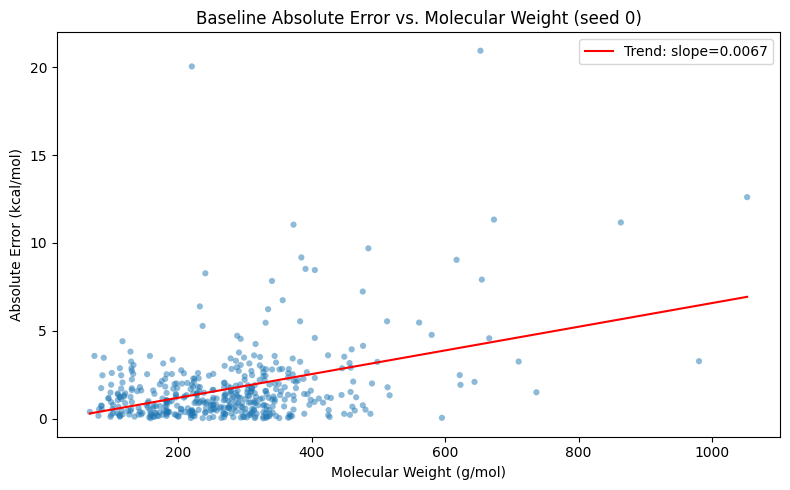

Correlation between MW and absolute error: 0.398


In [3]:
#BINNING THE BASELINE ERRORS BY MW (TERTILES OF THE ACTUAL TEST-SET MW DISTRIBUTION) TO LOOK FOR A TREND BETWEEN MW AND ERROR. NOTHING NEW IS PREDICTED HERE
#THE LIPINSKI CATEGORIES ARE HIGHLY UNBALANCED, THEREFORE TERTILES ARE USED INSTEAD
lipinski_bins = [0, 300, 500, 1000, np.inf]
lipinski_labels = ["Lead-like (<300)", "Drug-like (300-500)", "Extended (500-1000)", ">1000"]
baseline_predictions["mw_lipinski_bin"] = pd.cut(baseline_predictions["MW"], bins=lipinski_bins, labels=lipinski_labels)
print(baseline_predictions["mw_lipinski_bin"].value_counts())

mw_bins = baseline_predictions["MW"].quantile([0, 1/3, 2/3, 1]).values                #SPLITS THE TEST SET INTO 3 BINS BASED ON MW
mw_labels = ["Small MW", "Medium MW", "Large MW"]
baseline_predictions["mw_bin"] = pd.cut(baseline_predictions["MW"], bins=mw_bins, labels=mw_labels, include_lowest=True)

mw_error_table = baseline_predictions.groupby("mw_bin", observed=True).agg(
    n=("abs_error", "count"),
    mw_range=("MW", lambda x: f"{x.min():.0f}-{x.max():.0f}"),
    mean_abs_error=("abs_error", "mean"),
    median_abs_error=("abs_error", "median"),
    mean_rel_error=("rel_error_pct", "mean"),
    median_rel_error=("rel_error_pct", "median"),
)
print(mw_error_table)

#SCATTER OF ERROR VS MW, CONTINUOUS TREND
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(baseline_predictions["MW"], baseline_predictions["abs_error"], alpha=0.5, s=20, edgecolor="none")
slope, intercept = np.polyfit(baseline_predictions["MW"], baseline_predictions["abs_error"], 1)
x_line = np.array([baseline_predictions["MW"].min(), baseline_predictions["MW"].max()])
ax.plot(x_line, slope * x_line + intercept, color="red", linewidth=1.5, label=f"Trend: slope={slope:.4f}")
ax.set_xlabel("Molecular Weight (g/mol)")
ax.set_ylabel("Absolute Error (kcal/mol)")
ax.set_title("Baseline Absolute Error vs. Molecular Weight (seed 0)")
ax.legend()
plt.tight_layout()
plt.savefig("plots_dHfus_error_vs_MW.png", dpi=150)
plt.show()

corr = np.corrcoef(baseline_predictions["MW"], baseline_predictions["abs_error"])[0, 1]
print(f"Correlation between MW and absolute error: {corr:.3f}")

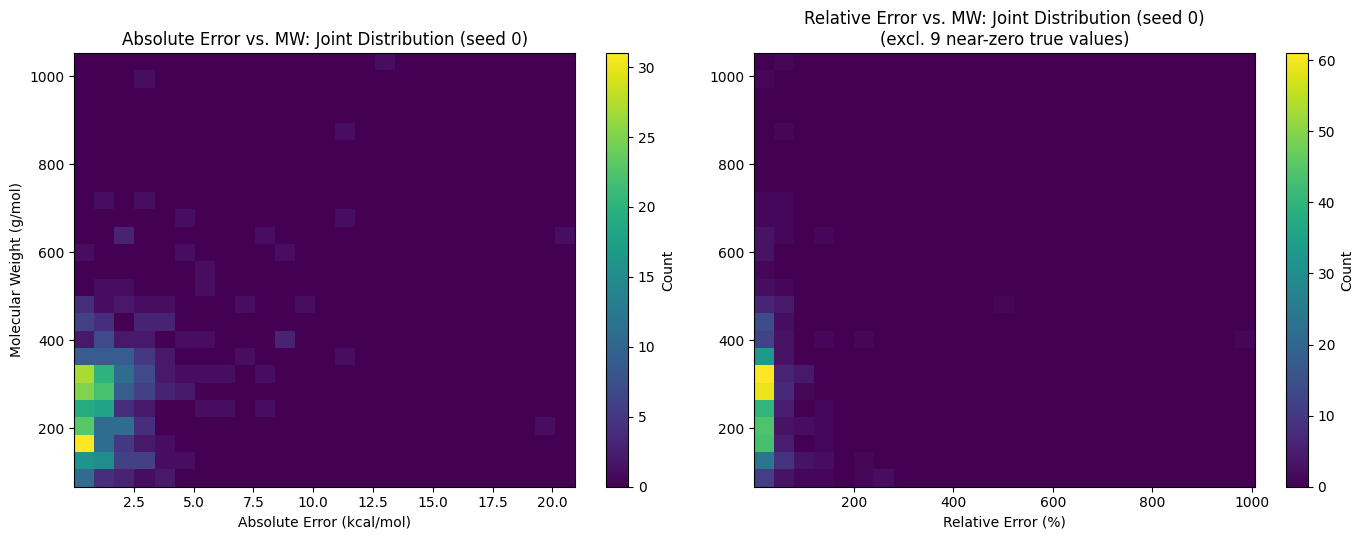

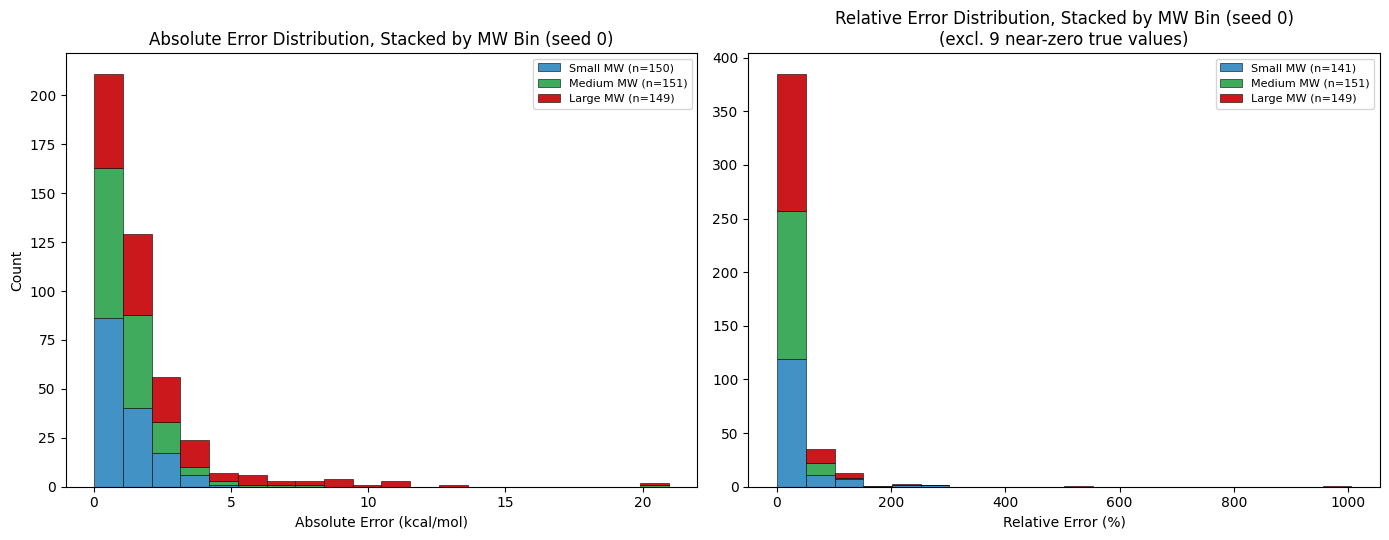

In [4]:
#2D HISTOGRAM: ABSOLUTE / RELATIVE ERROR (X) VS MW (Y), COLOUR = COUNT OF MOLECULES IN THAT CELL. SHOWS THE JOINT DISTRIBUTION RATHER THAN COLLAPSING MW INTO DISCRETE BINS
near_zero_threshold = 0.5
near_zero_mask = baseline_predictions["y_true"].abs() < near_zero_threshold              #RELATIVE ERROR IS UNSTABLE FOR NEAR-ZERO TRUE VALUES

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
h1 = axes[0].hist2d(baseline_predictions["abs_error"], baseline_predictions["MW"], bins=[25, 25], cmap="viridis")
cbar1 = plt.colorbar(h1[3], ax=axes[0])
cbar1.set_label("Count")
axes[0].set_xlabel("Absolute Error (kcal/mol)")
axes[0].set_ylabel("Molecular Weight (g/mol)")
axes[0].set_title("Absolute Error vs. MW: Joint Distribution (seed 0)")

rel_subset = baseline_predictions[~near_zero_mask]
h2 = axes[1].hist2d(rel_subset["rel_error_pct"], rel_subset["MW"], bins=[25, 25], cmap="viridis")
cbar2 = plt.colorbar(h2[3], ax=axes[1])
cbar2.set_label("Count")
axes[1].set_xlabel("Relative Error (%)")
axes[1].set_title(f"Relative Error vs. MW: Joint Distribution (seed 0)\n(excl. {near_zero_mask.sum()} near-zero true values)")
plt.tight_layout()
plt.savefig("plots_dHfus_error_MW_2Dhist.png", dpi=150)
plt.show()

#STACKED HISTOGRAM: STANDARD ERROR HISTOGRAM WITH EACH BAR SEGMENTED BY MW BIN
mw_bin_order = ["Small MW", "Medium MW", "Large MW"]
mw_bin_colors = ["#4292c6", "#41ab5d", "#cb181d"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
abs_error_by_bin = [baseline_predictions.loc[baseline_predictions["mw_bin"] == b, "abs_error"] for b in mw_bin_order]
axes[0].hist(abs_error_by_bin, bins=20, stacked=True, color=mw_bin_colors,
             label=[f"{b} (n={len(d)})" for b, d in zip(mw_bin_order, abs_error_by_bin)], edgecolor="black", linewidth=0.4)
axes[0].set_xlabel("Absolute Error (kcal/mol)")
axes[0].set_ylabel("Count")
axes[0].set_title("Absolute Error Distribution, Stacked by MW Bin (seed 0)")
axes[0].legend(fontsize=8)

rel_error_by_bin = [rel_subset.loc[rel_subset["mw_bin"] == b, "rel_error_pct"] for b in mw_bin_order]
axes[1].hist(rel_error_by_bin, bins=20, stacked=True, color=mw_bin_colors,
             label=[f"{b} (n={len(d)})" for b, d in zip(mw_bin_order, rel_error_by_bin)], edgecolor="black", linewidth=0.4)
axes[1].set_xlabel("Relative Error (%)")
axes[1].set_title(f"Relative Error Distribution, Stacked by MW Bin (seed 0)\n(excl. {near_zero_mask.sum()} near-zero true values)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig("plots_dHfus_error_MW_stacked_hist.png", dpi=150)
plt.show()

In [5]:
#PART 1.2: DOES TRAINING ON ONLY SMALL OR ONLY LARGE MOLECULES HELP? THE MODELS WERE TRAINED BY run_mw_subsets.py, THIS NOTEBOOK ONLY READS THE RESULTS
#DESIGN: FOR EACH SEED THE BASELINE SCAFFOLD SPLIT IS REBUILT AND ITS SMALL-MW / LARGE-MW (BOTTOM / TOP THIRD) SUBSETS ARE TAKEN. THE SUBSET MODEL AND THE FULL BASELINE MODEL (SAME SEED) ARE COMPARED ON THE SAME TEST MOLECULES
mw_runs = pd.read_csv("mw_subsets_seeds_dHfus.csv")
print("Rows:", len(mw_runs), "| seeds:", [int(s) for s in sorted(mw_runs["seed"].unique())])      #SHOULD BE 20 ROWS, SEEDS 0-9
print(mw_runs.groupby("subset")[["n_train", "n_val", "n_test"]].mean().round(0))                    #AVERAGE SUBSET SIZES
print(pd.read_csv("mw_subsets_cutoffs_dHfus.csv"))                                                  #TERTILE CUTOFFS (g/mol)

Rows: 20 | seeds: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
          n_train  n_val  n_test
subset                          
large_MW   1134.0  177.0   191.0
small_MW   1304.0  103.0    94.0
      cutoff       MW
0  small_max  175.058
1  large_min  282.468


In [6]:
summary_rows = []
for subset in ["small_MW", "large_MW"]:
    s = mw_runs[mw_runs["subset"] == subset].sort_values("seed")
    for metric in ["mae", "rmse"]:
        sub_vals, full_vals = s[f"sub_{metric}"].values, s[f"full_{metric}"].values
        t_stat, p_val = stats.ttest_rel(sub_vals, full_vals)                         #PAIRED ACROSS SEEDS (SAME SPLIT, SAME TEST MOLECULES)
        summary_rows.append(dict(Subset=subset, Metric=metric.upper(),
                                 Full_baseline=f"{full_vals.mean():.3f} ± {full_vals.std(ddof=1):.3f}",
                                 Subset_trained=f"{sub_vals.mean():.3f} ± {sub_vals.std(ddof=1):.3f}",
                                 Difference=sub_vals.mean() - full_vals.mean(),
                                 Paired_p=p_val, Seeds_subset_better=int((sub_vals < full_vals).sum())))
mw_summary = pd.DataFrame(summary_rows)
print(mw_summary.round(3).to_string(index=False))
mw_summary.to_csv("dHfus_MW_subset_comparison.csv", index=False)

  Subset Metric Full_baseline Subset_trained  Difference  Paired_p  Seeds_subset_better
small_MW    MAE 1.222 ± 0.102  1.120 ± 0.110      -0.102     0.012                    9
small_MW   RMSE 1.747 ± 0.175  1.661 ± 0.244      -0.086     0.077                    8
large_MW    MAE 2.377 ± 0.312  2.407 ± 0.408       0.030     0.488                    3
large_MW   RMSE 4.419 ± 1.727  4.281 ± 1.794      -0.138     0.016                    8


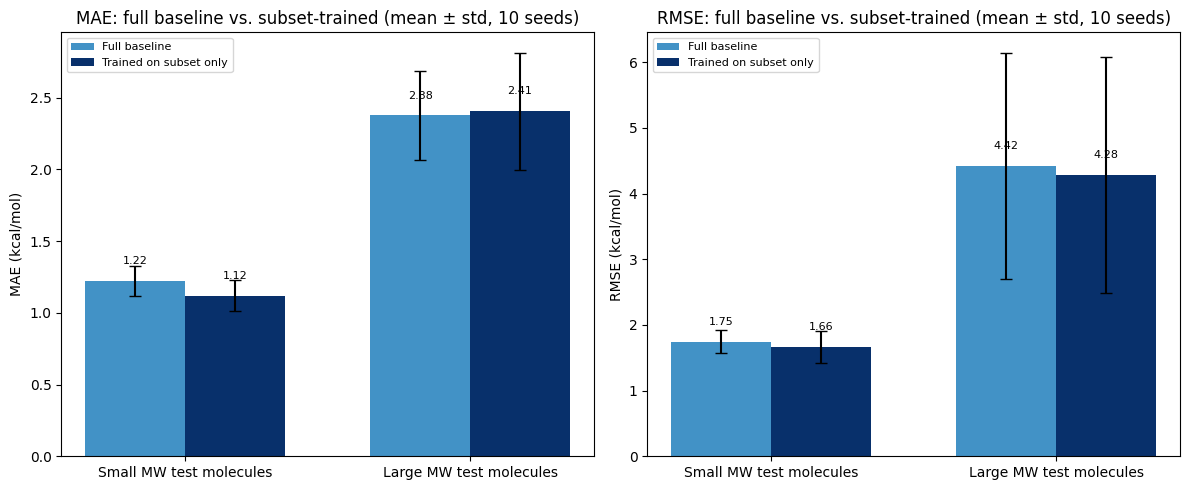

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, metric in zip(axes, ["mae", "rmse"]):
    x = np.arange(2)
    width = 0.35
    for i, (label, col, color) in enumerate([("Full baseline", f"full_{metric}", "#4292c6"), ("Trained on subset only", f"sub_{metric}", "#08306b")]):
        means = [mw_runs[mw_runs["subset"] == s][col].mean() for s in ["small_MW", "large_MW"]]
        stds = [mw_runs[mw_runs["subset"] == s][col].std() for s in ["small_MW", "large_MW"]]
        bars = ax.bar(x + (i - 0.5) * width, means, width, yerr=stds, capsize=4, color=color, label=label)
        for bar, v in zip(bars, means):
            ax.annotate(f"{v:.2f}", xy=(bar.get_x() + bar.get_width() / 2, v), xytext=(0, 12), textcoords="offset points", ha="center", fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(["Small MW test molecules", "Large MW test molecules"])
    ax.set_ylabel(f"{metric.upper()} (kcal/mol)")
    ax.set_title(f"{metric.upper()}: full baseline vs. subset-trained (mean ± std, 10 seeds)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("plots_dHfus_MW_subset_comparison.png", dpi=150)
plt.show()

         HB_total  rotatable_bonds
count  450.000000       450.000000
mean     3.693333         3.020000
std      3.165685         5.221341
min      0.000000         0.000000
25%      2.000000         0.000000
50%      3.000000         2.000000
75%      5.000000         4.000000
max     20.000000        49.000000
                    n  mean_abs_error  median_abs_error
hb_bin                                                 
Low H-bonding     163        1.295709          0.944849
Medium H-bonding  173        1.871432          1.236705
High H-bonding    114        2.051401          1.333099


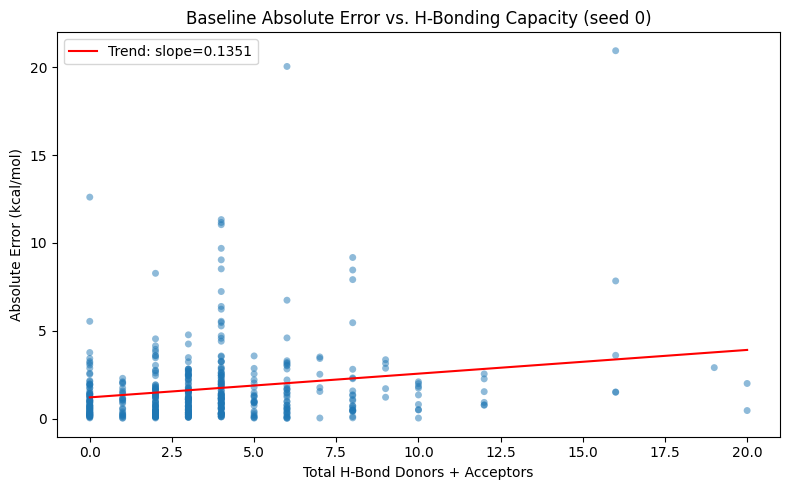

Correlation between H-bonding capacity and absolute error: 0.194


In [8]:
#PART 2: HYDROGEN BONDING ANALYSIS
#DETERMINES THE NUMBER OF HBA AND HBD FOR EACH MOLECULE
baseline_predictions["HBD"] = baseline_predictions["smiles"].apply(lambda s: Lipinski.NumHDonors(Chem.MolFromSmiles(s)))
baseline_predictions["HBA"] = baseline_predictions["smiles"].apply(lambda s: Lipinski.NumHAcceptors(Chem.MolFromSmiles(s)))
baseline_predictions["HB_total"] = baseline_predictions["HBD"] + baseline_predictions["HBA"]

#DETERMINES THE NUMBER OF ROTATABLE BONDS FOR EACH MOLECULE (USED IN PART 3)
baseline_predictions["rotatable_bonds"] = baseline_predictions["smiles"].apply(lambda s: Descriptors.NumRotatableBonds(Chem.MolFromSmiles(s)))
print(baseline_predictions[["HB_total", "rotatable_bonds"]].describe())

#BIN BY H-BONDING CAPACITY (TERTILES OF THE ACTUAL DATA DISTRIBUTION)
hb_bins = baseline_predictions["HB_total"].quantile([0, 1/3, 2/3, 1]).unique()
if len(hb_bins) < 4:                  #GUARDS AGAINST DUPLICATE BIN EDGES IF MANY MOLECULES SHARE THE SAME HB_total VALUE
    hb_bins = [baseline_predictions["HB_total"].min() - 0.5, 1.5, 3.5, baseline_predictions["HB_total"].max() + 0.5]
hb_labels = ["Low H-bonding", "Medium H-bonding", "High H-bonding"]
baseline_predictions["hb_bin"] = pd.cut(baseline_predictions["HB_total"], bins=hb_bins, labels=hb_labels, include_lowest=True)

hb_error_table = baseline_predictions.groupby("hb_bin", observed=True).agg(
    n=("abs_error", "count"),
    mean_abs_error=("abs_error", "mean"),
    median_abs_error=("abs_error", "median"),
)
print(hb_error_table)

#SCATTER PLOT OF BASELINE ABSOLUTE ERROR VS H-BONDING CAPACITY, WITH A LINEAR TRENDLINE
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(baseline_predictions["HB_total"], baseline_predictions["abs_error"], alpha=0.5, s=25, edgecolor="none")
slope, intercept = np.polyfit(baseline_predictions["HB_total"], baseline_predictions["abs_error"], 1)
x_line = np.array([baseline_predictions["HB_total"].min(), baseline_predictions["HB_total"].max()])
ax.plot(x_line, slope * x_line + intercept, color="red", linewidth=1.5, label=f"Trend: slope={slope:.4f}")
ax.set_xlabel("Total H-Bond Donors + Acceptors")
ax.set_ylabel("Absolute Error (kcal/mol)")
ax.set_title("Baseline Absolute Error vs. H-Bonding Capacity (seed 0)")
ax.legend()
plt.tight_layout()
plt.savefig("plots_dHfus_error_vs_HB.png", dpi=150)
plt.show()

corr_hb = np.corrcoef(baseline_predictions["HB_total"], baseline_predictions["abs_error"])[0, 1]
print(f"Correlation between H-bonding capacity and absolute error: {corr_hb:.3f}")

                        n  mean_abs_error  median_abs_error
rb_bin                                                     
Rigid                 274        1.347828          0.980734
Moderate flexibility  140        1.868536          1.242715
Highly flexible        36        3.831060          2.407266


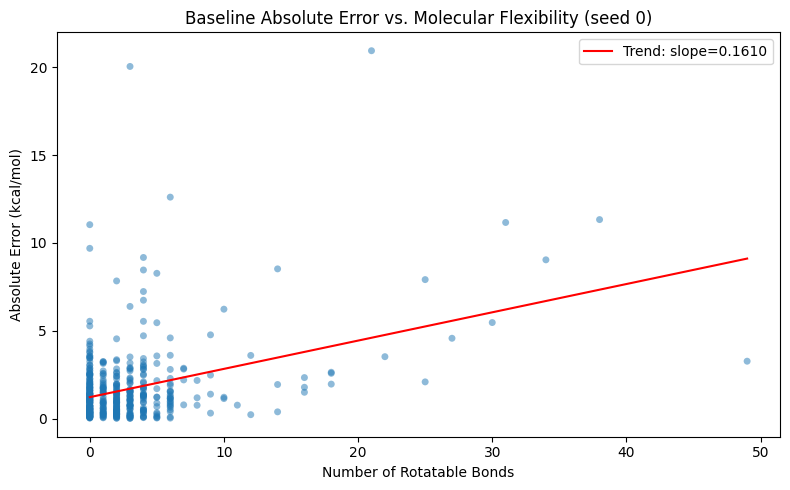

Correlation between rotatable bonds and absolute error: 0.381


In [9]:
#PART 3: FLEXIBILITY ANALYSIS (NUMBER OF ROTATABLE BONDS)
rb_bins = baseline_predictions["rotatable_bonds"].quantile([0, 1/3, 2/3, 1]).unique()
if len(rb_bins) < 4:
    rb_bins = [baseline_predictions["rotatable_bonds"].min() - 0.5, 2.5, 6.5, baseline_predictions["rotatable_bonds"].max() + 0.5]
rb_labels = ["Rigid", "Moderate flexibility", "Highly flexible"]
baseline_predictions["rb_bin"] = pd.cut(baseline_predictions["rotatable_bonds"], bins=rb_bins, labels=rb_labels, include_lowest=True)

rb_error_table = baseline_predictions.groupby("rb_bin", observed=True).agg(
    n=("abs_error", "count"),
    mean_abs_error=("abs_error", "mean"),
    median_abs_error=("abs_error", "median"),
)
print(rb_error_table)

#SCATTER PLOT OF BASELINE ABSOLUTE ERROR VS NUMBER OF ROTATABLE BONDS, WITH A LINEAR TRENDLINE
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(baseline_predictions["rotatable_bonds"], baseline_predictions["abs_error"], alpha=0.5, s=25, edgecolor="none")
slope, intercept = np.polyfit(baseline_predictions["rotatable_bonds"], baseline_predictions["abs_error"], 1)
x_line = np.array([baseline_predictions["rotatable_bonds"].min(), baseline_predictions["rotatable_bonds"].max()])
ax.plot(x_line, slope * x_line + intercept, color="red", linewidth=1.5, label=f"Trend: slope={slope:.4f}")
ax.set_xlabel("Number of Rotatable Bonds")
ax.set_ylabel("Absolute Error (kcal/mol)")
ax.set_title("Baseline Absolute Error vs. Molecular Flexibility (seed 0)")
ax.legend()
plt.tight_layout()
plt.savefig("plots_dHfus_error_vs_rotatable.png", dpi=150)
plt.show()

corr_rb = np.corrcoef(baseline_predictions["rotatable_bonds"], baseline_predictions["abs_error"])[0, 1]
print(f"Correlation between rotatable bonds and absolute error: {corr_rb:.3f}")

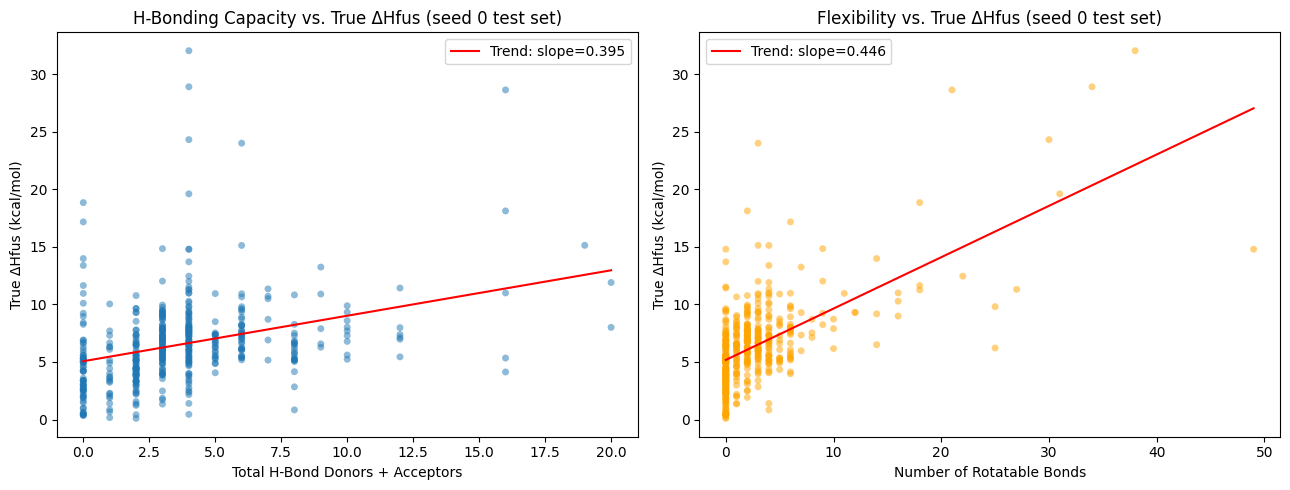

Correlation: H-bonding capacity vs true ΔHfus:  +0.334
Correlation: rotatable bonds vs true ΔHfus:     +0.622
Correlation: H-bonding capacity vs MW:  +0.312
Correlation: rotatable bonds vs MW:      +0.630


In [10]:
#EFFECT OF H-BONDING AND FLEXIBILITY ON THE TRUE ΔHfus VALUE ITSELF
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(baseline_predictions["HB_total"], baseline_predictions["y_true"], alpha=0.5, s=25, edgecolor="none")
slope_hb, intercept_hb = np.polyfit(baseline_predictions["HB_total"], baseline_predictions["y_true"], 1)
x_hb = np.array([baseline_predictions["HB_total"].min(), baseline_predictions["HB_total"].max()])
axes[0].plot(x_hb, slope_hb * x_hb + intercept_hb, color="red", linewidth=1.5, label=f"Trend: slope={slope_hb:.3f}")
axes[0].set_xlabel("Total H-Bond Donors + Acceptors")
axes[0].set_ylabel("True ΔHfus (kcal/mol)")
axes[0].set_title("H-Bonding Capacity vs. True ΔHfus (seed 0 test set)")
axes[0].legend()

axes[1].scatter(baseline_predictions["rotatable_bonds"], baseline_predictions["y_true"], alpha=0.5, s=25, edgecolor="none", color="orange")
slope_rb, intercept_rb = np.polyfit(baseline_predictions["rotatable_bonds"], baseline_predictions["y_true"], 1)
x_rb = np.array([baseline_predictions["rotatable_bonds"].min(), baseline_predictions["rotatable_bonds"].max()])
axes[1].plot(x_rb, slope_rb * x_rb + intercept_rb, color="red", linewidth=1.5, label=f"Trend: slope={slope_rb:.3f}")
axes[1].set_xlabel("Number of Rotatable Bonds")
axes[1].set_ylabel("True ΔHfus (kcal/mol)")
axes[1].set_title("Flexibility vs. True ΔHfus (seed 0 test set)")
axes[1].legend()
plt.tight_layout()
plt.savefig("plots_dHfus_true_value_vs_HB_and_flexibility.png", dpi=150)
plt.show()

corr_hb_true = np.corrcoef(baseline_predictions["HB_total"], baseline_predictions["y_true"])[0, 1]
corr_rb_true = np.corrcoef(baseline_predictions["rotatable_bonds"], baseline_predictions["y_true"])[0, 1]
print(f"Correlation: H-bonding capacity vs true ΔHfus:  {corr_hb_true:+.3f}")
print(f"Correlation: rotatable bonds vs true ΔHfus:     {corr_rb_true:+.3f}")

#DO HB / FLEXIBILITY CORRELATE WITH MW (CONFOUNDING CHECK)
corr_hb_mw = np.corrcoef(baseline_predictions["HB_total"], baseline_predictions["MW"])[0, 1]
corr_rb_mw = np.corrcoef(baseline_predictions["rotatable_bonds"], baseline_predictions["MW"])[0, 1]
print(f"Correlation: H-bonding capacity vs MW:  {corr_hb_mw:+.3f}")
print(f"Correlation: rotatable bonds vs MW:      {corr_rb_mw:+.3f}")

In [ ]:
#MODEL VS. JOBACK: TESTS WHETHER THE MODEL OUTPERFORMS JOBACK WHERE JOBACK IS KNOWN TO STRUGGLE (INTERMOLECULAR EFFECTS)
from chemprop_utils import joback_predict_dHfus

#COMPUTE JOBACK'S PREDICTION AND ERROR FOR EVERY TEST-SET MOLECULE (NaN IF UNASSIGNABLE GROUPS)
baseline_predictions["joback_pred"] = baseline_predictions["smiles"].apply(joback_predict_dHfus)
joback_valid_mask = baseline_predictions["joback_pred"].notna()
print(f"Joback predictions available for {joback_valid_mask.sum()} / {len(baseline_predictions)} test molecules")
baseline_predictions["joback_abs_error"] = np.abs(baseline_predictions["joback_pred"] - baseline_predictions["y_true"])

#RESTRICT THE COMPARISON TO MOLECULES WHERE BOTH THE MODEL AND JOBACK HAVE A VALID PREDICTION (MATCHED COMPARISON)
comparison_data = baseline_predictions[joback_valid_mask].copy()

hb_comparison_table = comparison_data.groupby("hb_bin", observed=True).agg(
    n=("abs_error", "count"), model_mean_error=("abs_error", "mean"), joback_mean_error=("joback_abs_error", "mean"))
hb_comparison_table["model_advantage"] = hb_comparison_table["joback_mean_error"] - hb_comparison_table["model_mean_error"]
print(hb_comparison_table)

rb_comparison_table = comparison_data.groupby("rb_bin", observed=True).agg(
    n=("abs_error", "count"), model_mean_error=("abs_error", "mean"), joback_mean_error=("joback_abs_error", "mean"))
rb_comparison_table["model_advantage"] = rb_comparison_table["joback_mean_error"] - rb_comparison_table["model_mean_error"]
print(rb_comparison_table)

Joback predictions available for 410 / 450 test molecules
                    n  model_mean_error  joback_mean_error  model_advantage
hb_bin                                                                     
Low H-bonding     158          1.308583           1.857385         0.548802
Medium H-bonding  156          1.874629           2.775359         0.900730
High H-bonding     96          1.999913           4.455496         2.455583
                        n  model_mean_error  joback_mean_error  \
rb_bin                                                           
Rigid                 251          1.365045           2.097286   
Moderate flexibility  124          1.721890           3.407353   
Highly flexible        35          3.858550           5.863431   

                      model_advantage  
rb_bin                                 
Rigid                        0.732241  
Moderate flexibility         1.685463  
Highly flexible              2.004881  


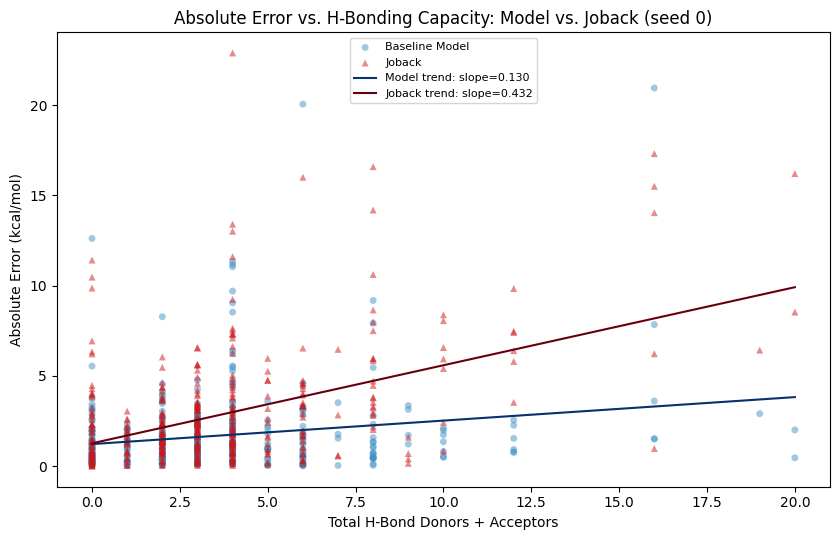

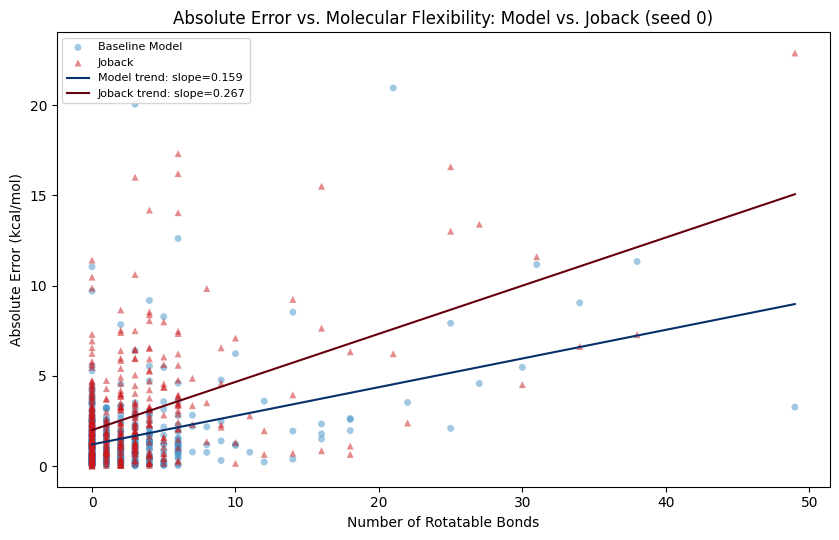

In [12]:
#H-BONDING AND FLEXIBILITY VS ABSOLUTE ERROR, MODEL AND JOBACK OVERLAID
for xcol, xlabel, title, fname in [
        ("HB_total", "Total H-Bond Donors + Acceptors", "Absolute Error vs. H-Bonding Capacity: Model vs. Joback (seed 0)", "plots_dHfus_error_vs_HB_with_joback.png"),
        ("rotatable_bonds", "Number of Rotatable Bonds", "Absolute Error vs. Molecular Flexibility: Model vs. Joback (seed 0)", "plots_dHfus_error_vs_rotatable_with_joback.png")]:
    fig, ax = plt.subplots(figsize=(8.5, 5.5))
    ax.scatter(comparison_data[xcol], comparison_data["abs_error"], alpha=0.5, s=25, color="#4292c6", marker="o", edgecolor="none", label="Baseline Model")
    ax.scatter(comparison_data[xcol], comparison_data["joback_abs_error"], alpha=0.5, s=25, color="#cb181d", marker="^", edgecolor="none", label="Joback")
    for col, color in [("abs_error", "#08306b"), ("joback_abs_error", "#67000d")]:           #TRENDLINE FOR EACH SERIES
        slope, intercept = np.polyfit(comparison_data[xcol], comparison_data[col], 1)
        x_line = np.array([comparison_data[xcol].min(), comparison_data[xcol].max()])
        ax.plot(x_line, slope * x_line + intercept, color=color, linewidth=1.5,
                label=f"{'Model' if col == 'abs_error' else 'Joback'} trend: slope={slope:.3f}")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Absolute Error (kcal/mol)")
    ax.set_title(title)
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(fname, dpi=150)
    plt.show()

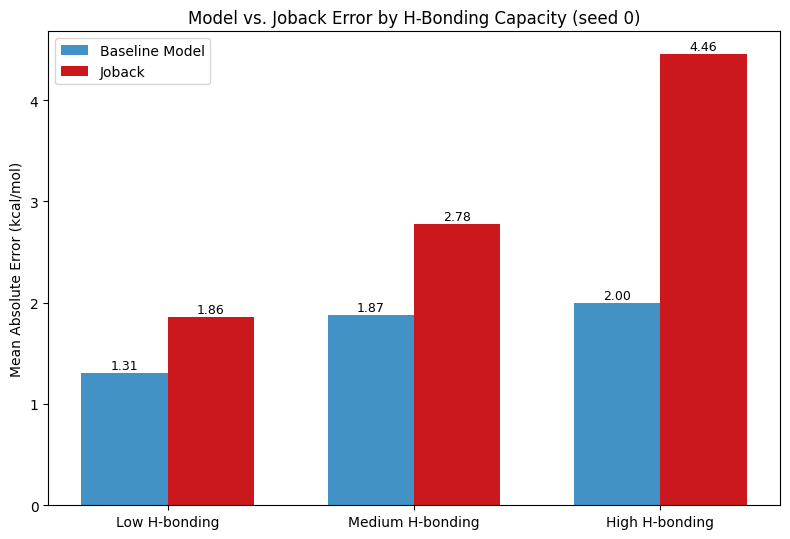

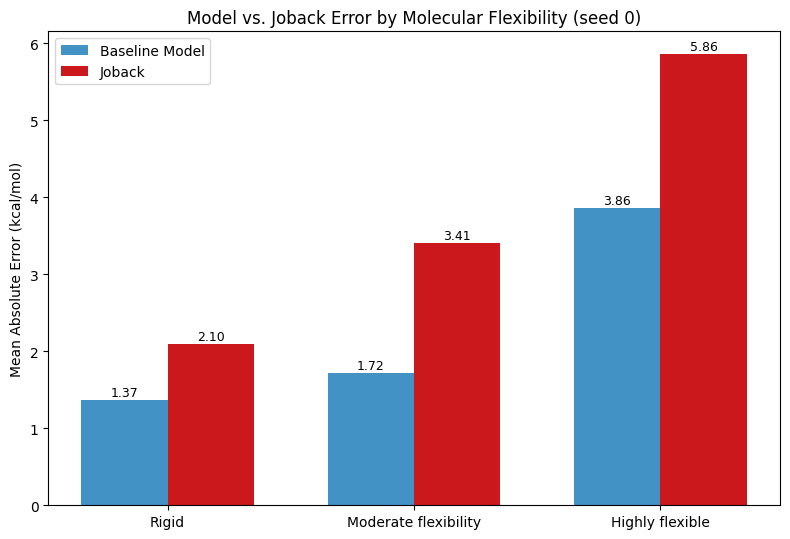

In [13]:
#GROUPED BAR CHARTS: MODEL VS. JOBACK ERROR PER H-BONDING BIN AND PER FLEXIBILITY BIN
for table, ylabel_title, fname in [
        (hb_comparison_table, "Model vs. Joback Error by H-Bonding Capacity (seed 0)", "plots_dHfus_model_vs_joback_by_HB.png"),
        (rb_comparison_table, "Model vs. Joback Error by Molecular Flexibility (seed 0)", "plots_dHfus_model_vs_joback_by_rotatable.png")]:
    fig, ax = plt.subplots(figsize=(8, 5.5))
    x = np.arange(len(table))
    width = 0.35
    bars_model = ax.bar(x - width / 2, table["model_mean_error"], width, label="Baseline Model", color="#4292c6")
    bars_joback = ax.bar(x + width / 2, table["joback_mean_error"], width, label="Joback", color="#cb181d")
    for bars in [bars_model, bars_joback]:
        for bar in bars:
            height = bar.get_height()
            ax.annotate(f"{height:.2f}", xy=(bar.get_x() + bar.get_width() / 2, height), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
    ax.set_xticks(x)
    ax.set_xticklabels(table.index)
    ax.set_ylabel("Mean Absolute Error (kcal/mol)")
    ax.set_title(ylabel_title)
    ax.legend()
    plt.tight_layout()
    plt.savefig(fname, dpi=150)
    plt.show()

In [14]:
#PART 1.2 (Tm): DOES TRAINING ON ONLY SMALL OR ONLY LARGE MOLECULES HELP? THE MODELS WERE TRAINED BY run_mw_subsets.py, THIS NOTEBOOK ONLY READS THE RESULTS
mw_runs_tm = pd.read_csv("mw_subsets_seeds_Tm.csv")
print("Rows:", len(mw_runs_tm), "| seeds:", [int(s) for s in sorted(mw_runs_tm["seed"].unique())])    #SHOULD BE 20 ROWS, SEEDS 0-9
print(mw_runs_tm.groupby("subset")[["n_train", "n_val", "n_test"]].mean().round(0))                  #AVERAGE SUBSET SIZES
print(pd.read_csv("mw_subsets_cutoffs_Tm.csv"))                                                     #TERTILE CUTOFFS (g/mol)

Rows: 20 | seeds: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
          n_train  n_val  n_test
subset                          
large_MW   2637.0  318.0   379.0
small_MW   2716.0  347.0   271.0
      cutoff       MW
0  small_max  271.320
1  large_min  376.432


In [15]:
summary_rows = []
for subset in ["small_MW", "large_MW"]:
    s = mw_runs_tm[mw_runs_tm["subset"] == subset].sort_values("seed")
    for metric in ["mae", "rmse"]:
        sub_vals, full_vals = s[f"sub_{metric}"].values, s[f"full_{metric}"].values
        t_stat, p_val = stats.ttest_rel(sub_vals, full_vals)                         #PAIRED ACROSS SEEDS (SAME SPLIT, SAME TEST MOLECULES)
        summary_rows.append(dict(Subset=subset, Metric=metric.upper(),
                                 Full_baseline=f"{full_vals.mean():.2f} ± {full_vals.std(ddof=1):.2f}",
                                 Subset_trained=f"{sub_vals.mean():.2f} ± {sub_vals.std(ddof=1):.2f}",
                                 Difference=sub_vals.mean() - full_vals.mean(),
                                 Paired_p=p_val, Seeds_subset_better=int((sub_vals < full_vals).sum())))
mw_summary_tm = pd.DataFrame(summary_rows)
print(mw_summary_tm.round(3).to_string(index=False))
mw_summary_tm.to_csv("Tm_MW_subset_comparison.csv", index=False)

  Subset Metric Full_baseline Subset_trained  Difference  Paired_p  Seeds_subset_better
small_MW    MAE  33.89 ± 1.63   34.85 ± 1.64       0.960     0.009                    2
small_MW   RMSE  44.90 ± 2.82   46.08 ± 2.67       1.179     0.048                    1
large_MW    MAE  33.22 ± 1.55   35.01 ± 1.23       1.789     0.001                    1
large_MW   RMSE  42.79 ± 1.91   44.86 ± 1.81       2.066     0.002                    1


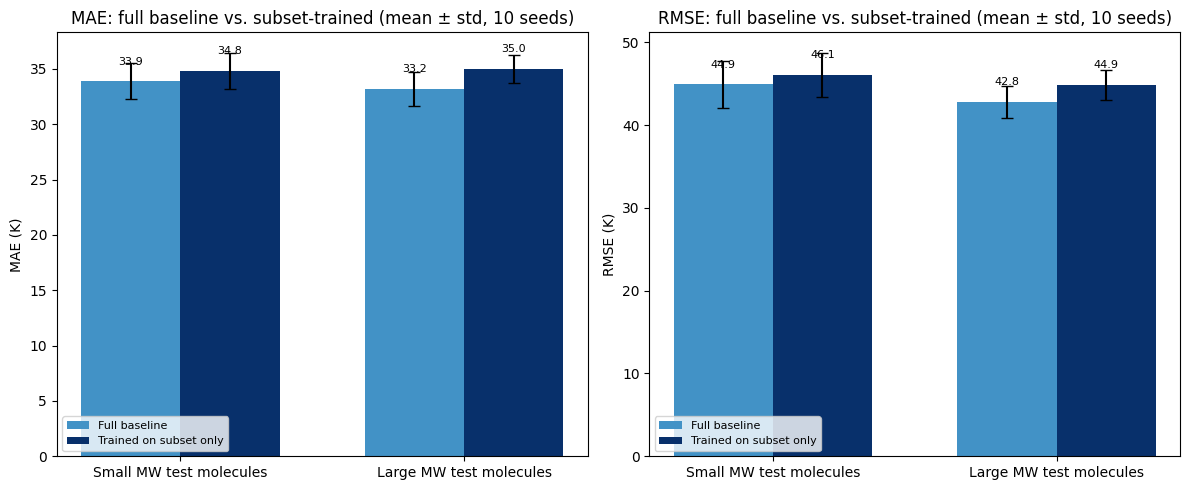

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, metric in zip(axes, ["mae", "rmse"]):
    x = np.arange(2)
    width = 0.35
    for i, (label, col, color) in enumerate([("Full baseline", f"full_{metric}", "#4292c6"), ("Trained on subset only", f"sub_{metric}", "#08306b")]):
        means = [mw_runs_tm[mw_runs_tm["subset"] == s][col].mean() for s in ["small_MW", "large_MW"]]
        stds = [mw_runs_tm[mw_runs_tm["subset"] == s][col].std() for s in ["small_MW", "large_MW"]]
        bars = ax.bar(x + (i - 0.5) * width, means, width, yerr=stds, capsize=4, color=color, label=label)
        for bar, v in zip(bars, means):
            ax.annotate(f"{v:.1f}", xy=(bar.get_x() + bar.get_width() / 2, v), xytext=(0, 12), textcoords="offset points", ha="center", fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(["Small MW test molecules", "Large MW test molecules"])
    ax.set_ylabel(f"{metric.upper()} (K)")
    ax.set_title(f"{metric.upper()}: full baseline vs. subset-trained (mean ± std, 10 seeds)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("plots_Tm_MW_subset_comparison.png", dpi=150)
plt.show()